# 01 - Theoretical Model: Law of the Few (Galeotti & Goyal, 2010)

This notebook demonstrates the **Law of the Few** model, where individuals choose between
personally acquiring information and forming strategic connections to others who hold
information. The model produces core-periphery network structures with a small number
of information-rich **hubs** and many **spokes** who free-ride on hub information.

### Key Theoretical Insights

1. In equilibrium, each player either acquires information personally or forms links
   with others who do, leading to a natural hub-spoke structure.
2. Aggregate information in equilibrium equals the optimal level for an isolated player
   (given by `y_hat`).
3. The number of hubs is bounded and becomes a vanishingly small fraction of the
   population as `n` grows -- the "Law of the Few".

In [2]:
import sys
sys.path.insert(0, '..')

import numpy as np
import matplotlib.pyplot as plt

from src.models.law_of_few import LawOfFewModel, run_simulation

## Parameter Configuration

| Parameter | Description | Value |
|-----------|-------------|-------|
| `n` | Number of players in the network | 200 |
| `c` | Cost of acquiring one unit of information | 1.0 |
| `k` | Cost of forming a link to another player | 0.5 |
| `y_hat` | Optimal information level for an isolated player | 1.0 |
| `max_steps` | Maximum number of best-response update rounds | 300 |
| `seed` | Random seed for reproducibility | 42 |

The condition `k < c * y_hat` ensures that link formation is cheaper than full
self-acquisition, making hub formation viable.

In [3]:
# Simulation parameters
N = 200
C = 1.0
K = 0.5
Y_HAT = 1.0
MAX_STEPS = 300
SEED = 42

print(f"Parameters: n={N}, c={C}, k={K}, y_hat={Y_HAT}")
print(f"k < c*y_hat? {K} < {C * Y_HAT} => {K < C * Y_HAT}")
print(f"Link formation is {'viable' if K < C * Y_HAT else 'NOT viable'}.")

Parameters: n=200, c=1.0, k=0.5, y_hat=1.0
k < c*y_hat? 0.5 < 1.0 => True
Link formation is viable.


## Run the Simulation

The `run_simulation` function performs best-response dynamics: in each step, every
player updates their information-acquisition level and linking strategy to maximise
their individual payoff. The simulation terminates when no player changes strategy
(convergence) or when `max_steps` is reached.

The utility for player *i* is:

$$U_i = f\!\left(x_i + \sum_{j \in N_i} x_j\right) - c \cdot x_i - k \cdot |\{j : g_{ij} = 1\}|$$

where $f(y) = \ln(1 + y)$ is a concave benefit function.

Starting simulation with 200 players (c=1.0, k=0.5, y_hat=1.0)...


Simulating network evolution:  33%|███▎      | 100/300 [00:09<00:18, 10.85it/s]



Converged after 101 steps!

Core size: 1/200 = 0.50%
Total information: 1.0000 (target: 1.0)


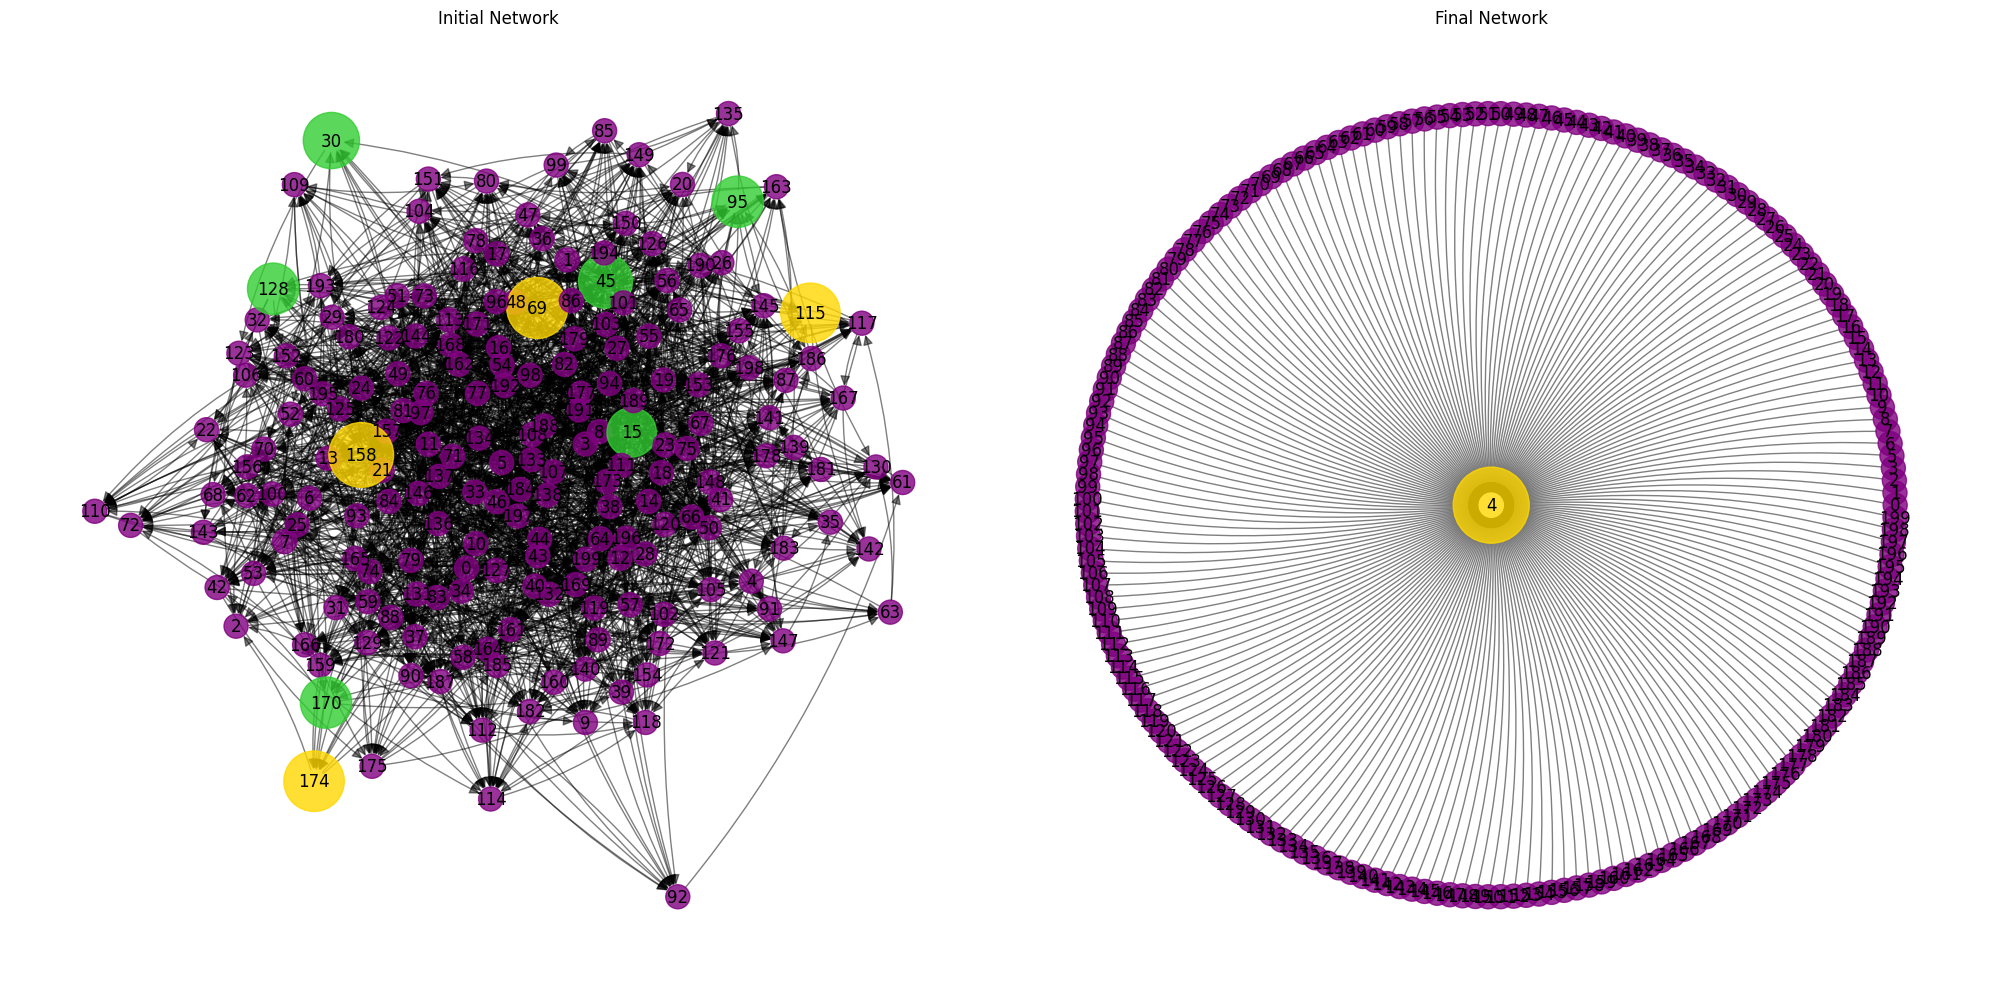

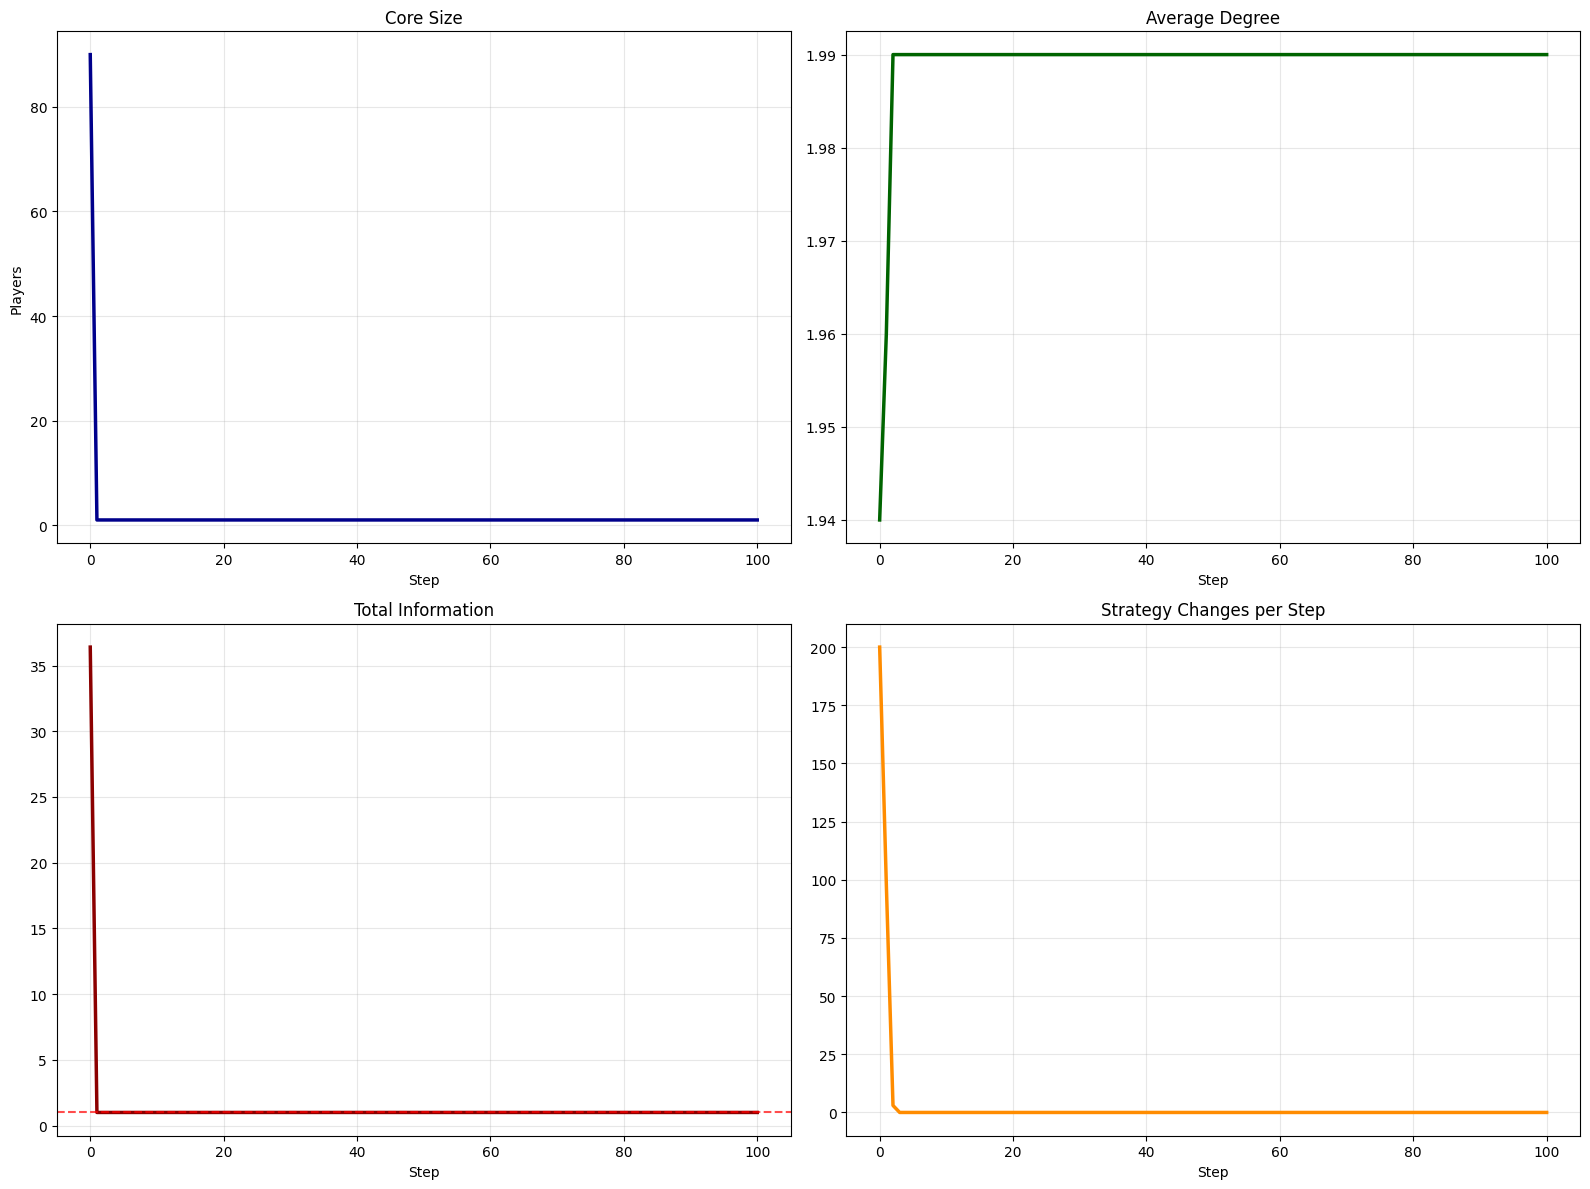

In [5]:
model, history = run_simulation(
    n=N,
    c=C,
    k=K,
    y_hat=Y_HAT,
    max_steps=MAX_STEPS,
    convergence_threshold=3,
    seed=SEED,
)

plt.show()

## Analyse the Final Network

After convergence we inspect:
- **Core size**: how many players hold significant information ($x_i > 0.1 \cdot \hat{y}$).
- **Total information**: should converge close to `y_hat`.
- **Degree distribution**: spokes link to hubs, creating a skewed distribution.

In [6]:
final_x = history['x'][-1]
final_g = history['g'][-1]

threshold = 0.1 * model.y_hat
core_players = [i for i, xi in enumerate(final_x) if xi > threshold]
periphery_players = [i for i, xi in enumerate(final_x) if xi <= threshold]

print(f"Core (hub) players:      {len(core_players)} / {N} ({len(core_players)/N:.1%})")
print(f"Periphery (spoke) players: {len(periphery_players)} / {N} ({len(periphery_players)/N:.1%})")
print(f"Total information:       {np.sum(final_x):.4f} (target y_hat = {Y_HAT})")
print(f"Max information level:   {np.max(final_x):.4f}")
print(f"Mean information level:  {np.mean(final_x):.4f}")

Core (hub) players:      1 / 200 (0.5%)
Periphery (spoke) players: 199 / 200 (99.5%)
Total information:       1.0000 (target y_hat = 1.0)
Max information level:   1.0000
Mean information level:  0.0050


## Visualise the Final Network (Circular Layout)

Gold nodes are **hubs** (high information), green nodes are **medium** information
holders, and purple nodes are **spokes** (low or zero information). Node size is
proportional to the amount of information held.

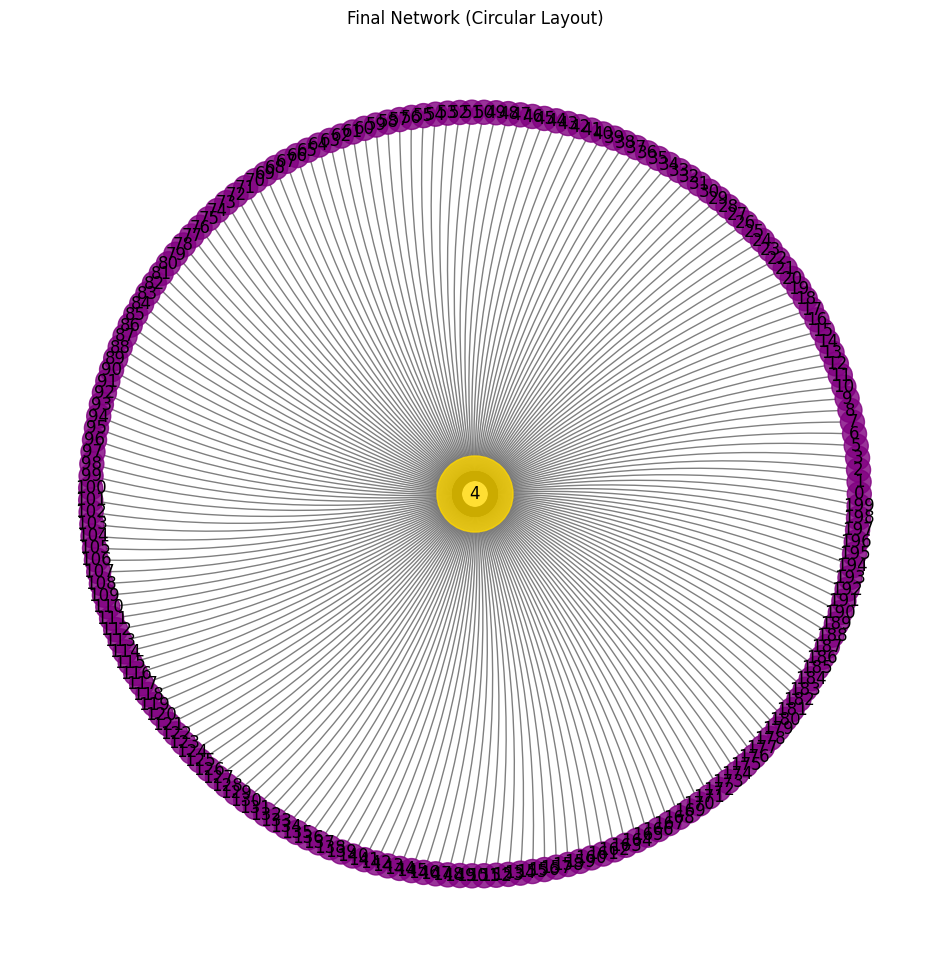

In [7]:
fig, ax = plt.subplots(figsize=(12, 12))
model.plot_network(ax=ax, title='Final Network (Circular Layout)', use_circular_layout=True)
plt.show()

## Simulation Metrics Over Time

The four-panel plot below tracks:
1. **Core size** -- the number of information-acquiring players.
2. **Average degree** -- mean number of connections per player.
3. **Total information** -- should approach `y_hat` (dashed red line).
4. **Strategy changes per step** -- should decline as the network approaches equilibrium.

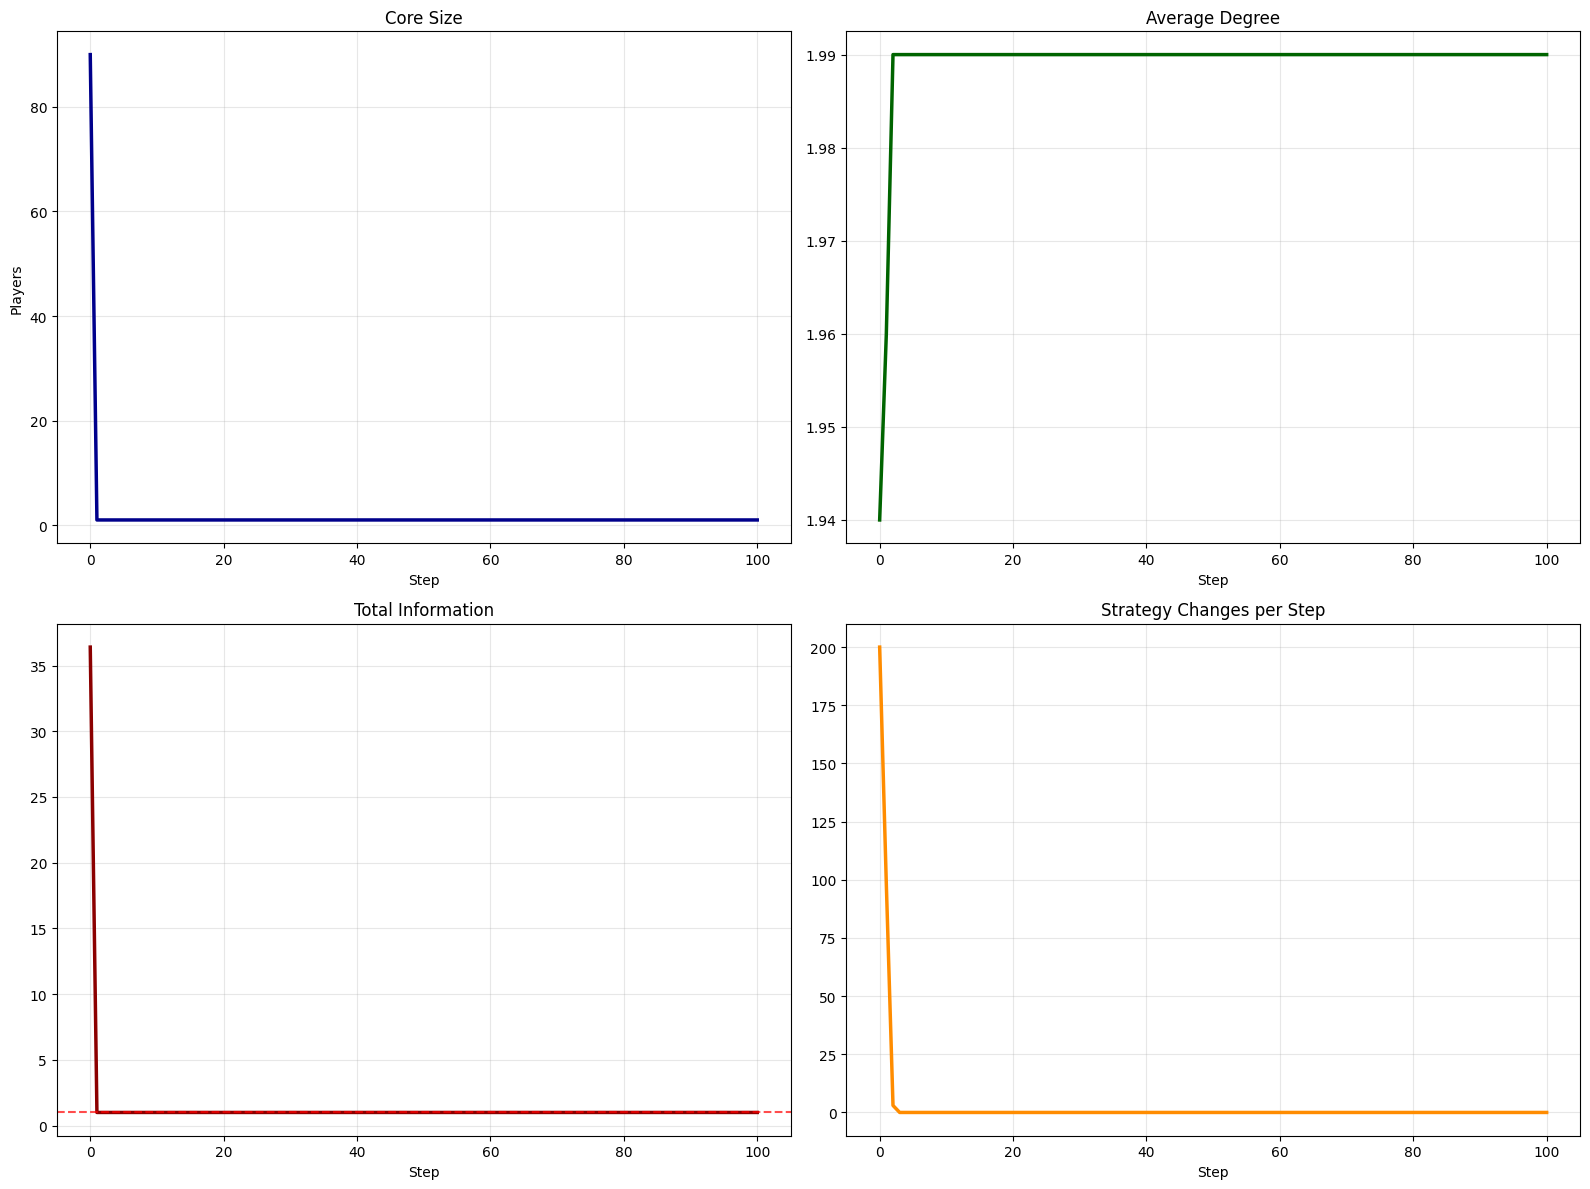

In [8]:
fig = model.plot_metrics(history)
plt.show()

## Information Distribution

A histogram of per-player information levels in the final network confirms the
Law of the Few: the distribution is heavily right-skewed, with most players
holding zero information and a few hubs holding most of it.

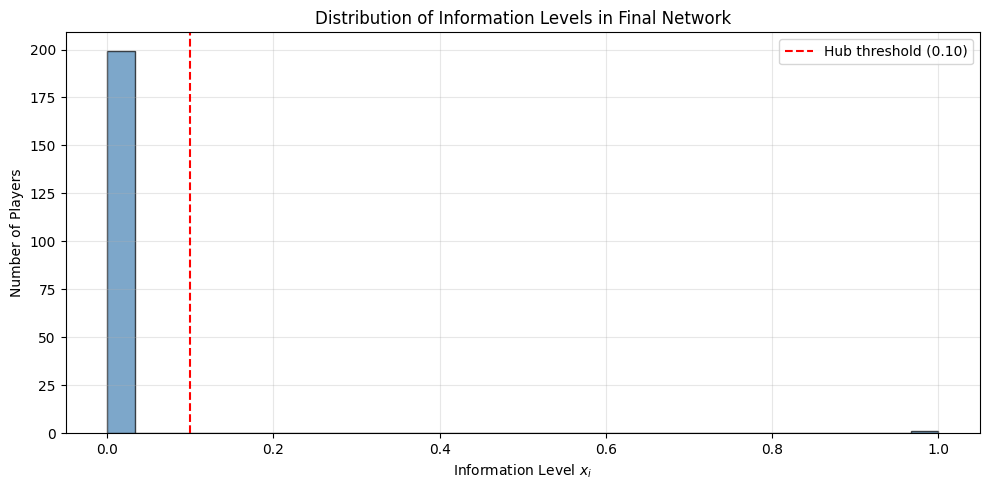

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(final_x, bins=30, edgecolor='black', alpha=0.7, color='steelblue')
ax.axvline(threshold, color='red', linestyle='--', label=f'Hub threshold ({threshold:.2f})')
ax.set_xlabel('Information Level $x_i$')
ax.set_ylabel('Number of Players')
ax.set_title('Distribution of Information Levels in Final Network')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()